
# T3.3 EIT-003 Lifecycle Environmental Performance Model

READ.ME 

This notebook is the **shared foundation** for the EIT-003 pipeline. It contains everything that is independent of runtime event data and must be run once before EIT-001 or EIT-002 can be used.

- Environment setup (Brightway project initialisation ecoinvent and BONSAI database installation)
- Foreground model: REED foreground database imported from `REED_model_*.xlsx`
- Baseline LCA results 
  - KOMATSU results
  - WWR results
  - GOIMEK A1 / A2 / A3 results
- Analysis & visualisation (Contribution analysis, contribution plots)
- Reusable LCA functions (`lca_score`, `run_contribution_analysis`, `lcia_for_activity_with_scenario`)

Run this notebook **once** to set up the Brightway project.

> EIT-001 and EIT-002 both assume this project is initialised and call into it.


### 1. Importers

#### 1.1 Brightway

In [1]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config
import bw_processing as bwp
from bw2io.strategies.generic import set_code_by_activity_hash


import matplotlib.pyplot as plt
import d3graph
import polyviz

from datetime import date

09:28:52+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [2]:
bi.remote.install_project(project_key="ecoinvent-3.10-biosphere", overwrite_existing=True)

Restoring project backup archive - this could take a few minutes...
Restored project: ecoinvent-3.10-biosphere


'ecoinvent-3.10-biosphere'

In [3]:
config = Config()

In [4]:
bd.projects.set_current(config.PROJECT_NAME)

In [5]:
import import_db

#### 1.2 Foreground database 

In [6]:
bonsai = bd.Database('BONSAI_V2.1.3')
bonsai_bio = bd.Database('BONSAI_V2.1.3 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')

In [7]:
bd.databases

Databases dictionary with 4 object(s):
	BONSAI_V2.1.3
	BONSAI_V2.1.3 biosphere
	ecoinvent-3.10-biosphere
	reed

In [8]:
from bw2io.importers import ExcelImporter
from reed.utils import Config

importer  = ExcelImporter(config.REED_PATH/'model'/'REED_model_20260407.xlsx',)
importer.apply_strategies()
importer.match_database(fields=['name','unit','location'])
importer.match_database(db_name=bonsai.name,fields=['name','unit','location','activity type'])
importer.match_database(db_name=bd.config.biosphere,fields=['name','categories','unit'])
reed = bd.Database('reed')

Extracted 6 worksheets in 0.93 seconds
Applying strategy: csv_restore_tuples
Applying strategy: csv_restore_booleans
Applying strategy: csv_numerize
Applying strategy: csv_drop_unknown
Applying strategy: csv_add_missing_exchanges_section
Applying strategy: normalize_units
Applying strategy: normalize_biosphere_categories
Applying strategy: normalize_biosphere_names
Applying strategy: strip_biosphere_exc_locations
Applying strategy: set_code_by_activity_hash
Applying strategy: link_iterable_by_fields
Applying strategy: assign_only_product_as_production
Applying strategy: link_technosphere_by_activity_hash
Applying strategy: drop_falsey_uncertainty_fields_but_keep_zeros
Applying strategy: convert_uncertainty_types_to_integers
Applying strategy: convert_activity_parameters_to_list
Applied 16 strategies in 1.79 seconds
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields


In [9]:
importer.statistics()

Graph statistics for `reed` importer:
77 graph nodes:
	None: 77
423 graph edges:
	technosphere: 344
	production: 77
	biosphere: 2
423 edges to the following databases:
	BONSAI_V2.1.3: 240
	reed: 181
	ecoinvent-3.10-biosphere: 2
0 unique unlinked edges (0 total):




(77, 423, 0, 0)

In [10]:
importer.write_database()

100%|██████████| 77/77 [00:00<00:00, 330.43it/s]


09:29:59+0200 [info     ] Vacuuming database            
Created database: reed


In [11]:
pd.DataFrame(importer.unlinked)

""


In [12]:
data_reed = [activity.as_dict() for activity in reed]
df_reed = pd.DataFrame(data_reed)


In [13]:
from IPython.display import display
display(df_reed[['name', 'comment', 'location', 'unit', 'database']])

,name,comment,location,unit,database
0,"flamecutting, natural gas",This process represents flamecutting. The data...,DE,hour,reed
1,alkyd paint,None,ES,ton,reed
2,boring,None,ES,hour,reed
3,alkyd paint,None,DE,ton,reed
4,"milling, soraluce",proxy for milling. Waiting for primary electri...,DE,hour,reed
...,...,...,...,...,...
72,"welding, robotic","draft for robotic welding process (MIG), missi...",GB,hour,reed
73,alkyd paint,None,GB,ton,reed
74,GOIMEK A3: machining,None,ES,unit,reed
75,"Soraluce, average",This inventory is calculated based on informat...,DE,unit,reed


In [14]:
bonsai = bd.Database('BONSAI_V2.1.3')
bonsai_bio = bd.Database('BONSAI_V2.1.3 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')
reed = bd.Database('reed')

In [15]:
bd.databases

Databases dictionary with 4 object(s):
	BONSAI_V2.1.3
	BONSAI_V2.1.3 biosphere
	ecoinvent-3.10-biosphere
	reed

#### 1.3 Sensordata

This part draws from defined functions in the script, sensordata_analysis.py. It imports the monitoring data and calculates the energy consumption per tool and connect the tools to the reed tools

In [16]:
from reed.sensordata_analysis import (
    run_sensordata_analysis,
    find_missing_op_type_tools,
    compute_event_totals,
    split_final_df_by_company_event,
    sum_by_reed_tool,
    split_final_df_by_company_event,
)

In [17]:
monitoring_data_path = config.REED_PATH/'Data'/"MonitoringData"/"Data"
tool_descriptions_path = config.REED_PATH/'Data'/"MonitoringData"

In [18]:
sensordata, event_summaries_df, ambiguous_company_tools, key_company_tools, key_reed_tools = run_sensordata_analysis(
    monitoring_data_path,
    tool_descriptions_path,
)
print(sensordata)

C:\Users\TimWeber\repos_20LCA\REED\reed\src\reed\sensordata_analysis.py:132: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f)


                                                  energy_consumption  \
company event_id                     Tool_Number                       
goimek  OF10001_G_BQC_S8CF2G         0.0                    8.154403   
                                     1.0                   24.300319   
                                     2.0                   10.289347   
                                     3.0                   14.673875   
                                     4.0                    0.930889   
...                                                              ...   
wwr     OF10005_SETUPS2_G_TWB_7SZ421 2694.0                 2.915730   
                                     2695.0                 1.068689   
                                     2696.0                 2.709187   
                                     2722.0                 0.631658   
                                     3350.0                23.502143   

                                                  Power_Active 

Identify tools that have different operation type in the key_company_tools. These tool numbers are removed from the key to avoid an ambigious key. These tool numbers will be assigned to the generic machining process in the reed database

In [19]:
print(ambiguous_company_tools)

   company  Tool_Number                   op_type_candidates
0   goimek            2                 [AUXILIARY, MILLING]
1   goimek            6                 [AUXILIARY, MILLING]
2   goimek           30                 [AUXILIARY, MILLING]
3   goimek           31                   [CHAMFER, MILLING]
4   goimek           44                 [AUXILIARY, MILLING]
5   goimek           45                 [AUXILIARY, MILLING]
6  komatsu            3           [AUXILIARY, ROUGH MILLING]
7  komatsu           48  [AUXILIARY, MILLING, ROUGH MILLING]
8  komatsu           50        [ROUGH BORING, ROUGH MILLING]
9  komatsu           72      [FINISH MILLING, ROUGH MILLING]


In [20]:
#Identify missing op type tools, e.g. tools that are in the monitoring data but not in tool descriptions
missing_tool_descriptions = find_missing_op_type_tools(sensordata)

In [21]:
#Compute total time and energy per event per company
event_totals = compute_event_totals(sensordata, event_summaries_df)

### 2. Integrating sensor data as scenario 

this section is missing a part about how to handle the processes that are not in hours?

In [22]:
from reed.swapping_data import (
    find_activities_by_name,
    build_scenarios_from_power_active,
    build_consumer_input_scenarios_from_hours,
    describe_scenarios,
    lcia_for_activity_with_scenario,
    find_subactivity_by_name_fragment,
    build_consumer_input_scenarios_from_hours_for_activity,
    get_product_id_for_activity,
)

Select which event you want to analyse

In [23]:
company = "goimek"
event_id = "OF10005_G_BQC_S8CF2G"
product = "GOIMEK total"
demand = 1

Start by selected the company and event_id where you want to swap in the sensordata

In [24]:
#Split sensordata by company and event
event_dfs = split_final_df_by_company_event(sensordata)

#Compute energy by reed tool for a specific company and event
tool_energy_by_company_and_event = sum_by_reed_tool(
    event_dfs[(company, event_id)]
)
print(tool_energy_by_company_and_event)

                                                          energy_consumption  \
company event_id             reed tool                                         
goimek  OF10005_G_BQC_S8CF2G drilling, soraluce                    28.517208   
                             generic machining, soraluce          115.554208   
                             milling, soraluce                     35.696639   

                                                              hours  \
company event_id             reed tool                                
goimek  OF10005_G_BQC_S8CF2G drilling, soraluce           50.165556   
                             generic machining, soraluce   9.222778   
                             milling, soraluce             3.079722   

                                                          Power_Active  
company event_id             reed tool                                  
goimek  OF10005_G_BQC_S8CF2G drilling, soraluce               0.568462  
                        


Find all processes present in the sensordata in the reed-database

In [25]:
tools = tool_energy_by_company_and_event.index.get_level_values("reed tool").unique()
found = {t: find_activities_by_name(reed, t, exact=False) for t in tools}
found

{'drilling, soraluce': ['drilling, soraluce' (kilogram, GB, None),
  'drilling, soraluce' (hour, DE, None),
  'drilling, soraluce' (hour, GB, None),
  'drilling, soraluce' (kilogram, DE, None),
  'drilling, soraluce' (kilogram, ES, None),
  'drilling, soraluce' (hour, ES, None)],
 'generic machining, soraluce': ['generic machining, soraluce' (hour, ES, None),
  'generic machining, soraluce' (kilogram, GB, None),
  'generic machining, soraluce' (hour, GB, None),
  'generic machining, soraluce' (hour, DE, None),
  'generic machining, soraluce' (kilogram, ES, None),
  'generic machining, soraluce' (kilogram, DE, None)],
 'milling, soraluce': ['milling, soraluce' (hour, DE, None),
  'milling, soraluce' (hour, GB, None),
  'milling, soraluce' (kilogram, ES, None),
  'milling, soraluce' (hour, ES, None),
  'milling, soraluce' (kilogram, DE, None),
  'milling, soraluce' (kilogram, GB, None)]}

Find subactivities called A3 for the product under study

In [26]:
product_activity = reed.get(name=product)

# Find the A3 activity inside KOMATSU total
a3_matches = find_subactivity_by_name_fragment(
    parent_activity=product_activity,
    name_fragment="A3",
)

print(a3_matches)
a3_activity = a3_matches[0]

['GOIMEK A3: machining' (unit, ES, None)]


In [27]:
soraluce_matches = find_subactivity_by_name_fragment(
    parent_activity=a3_activity,
    name_fragment="soraluce machining",
)

print(soraluce_matches)

soraluce_activity = soraluce_matches[0]

['Soraluce machining, GOIMEK' (unit, ES, None)]


In [28]:
#Identifying the electricity activity in bonsai to be able to compute the original electricity input amount for the activities found above
electricity = bonsai.get(name='production of electricity (market for)', location='GB', unit='TJ')

Create scenario where alle electricity inputs from the sensordata to the processes identified in found.

In [29]:
scenarios = build_scenarios_from_power_active(tool_energy_by_company_and_event, found, electricity)
scenarios


original  goimek_OF10005_G_BQC_S8CF2G
product            activity                                                 
294833522511208455 309954867223670785       0.0                     0.000002
                   309954867139784704       0.0                     0.000045
                   309954867185922048       0.0                     0.000042

The input of products in found to consuming activities are found and used to build scenarios.

In [30]:
consumer_scenarios = build_consumer_input_scenarios_from_hours_for_activity(
    tool_energy_by_company_and_event,
    found,
    consumer_activity=soraluce_activity,
)
consumer_scenarios

,,original,goimek_OF10005_G_BQC_S8CF2G
product,activity,,
309954867139784704,309954867286585344,0.000000,9.222778
309954867206893568,309954867286585344,29.705051,3.079722


In [31]:
full_scenario = pd.concat([scenarios, consumer_scenarios])

In [32]:
full_scenario_readable = describe_scenarios(full_scenario)
full_scenario_readable

,product_name,product_unit,activity_name,activity_unit,original,goimek_OF10005_G_BQC_S8CF2G
0,production of electricity (market for),TJ,"drilling, soraluce",hour,0.000000,0.000002
1,production of electricity (market for),TJ,"generic machining, soraluce",hour,0.000000,0.000045
2,production of electricity (market for),TJ,"milling, soraluce",hour,0.000000,0.000042
3,"generic machining, soraluce",hour,"Soraluce machining, GOIMEK",unit,0.000000,9.222778
4,"milling, soraluce",hour,"Soraluce machining, GOIMEK",unit,29.705051,3.079722


#### 3. Initial LCA scores

LCA score with sensor data

In [33]:
score, lca = lcia_for_activity_with_scenario(
    activity=product_activity,
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    scenario_col=None,     # "original" or None (for defined scenario)
    amount=demand
)
score


16162.455300776524

LCA score without sensor data

In [34]:
product_reed = product_activity
lca = product_reed.lca(method=config.lcia_gwp100)
lca.score

16385.014851335523

In [35]:
goimek_total = reed.get(name="GOIMEK total", location="ES", unit="unit")

In [38]:
bwa.print_recursive_calculation(goimek_total,
lcia_method=config.lcia_gwp100,max_level=1,cutoff=0.001)

Fraction of score | Absolute score | Amount | Activity
0001 | 1.639e+04 |     1 | 'GOIMEK total' (unit, ES, None)
  1.05 | 1.721e+04 |     1 | 'GOIMEK A1: material input' (unit, ES, None)
  0.0117 | 191.1 |     1 | 'GOIMEK A2: transport' (unit, ES, None)
  0.0298 | 488.8 |     1 | 'GOIMEK A3: machining' (unit, ES, None)
  -0.0919 | -1,506 |   0.8 | 'treatment of steel, industrial waste (market for)' (ton, ES, None)


### 4. Digital Product Passport

#### 4.1 Functions for DPP alignment

In [39]:
def lcia_score_for_named_input(
    parent_activity,
    name_fragment,
    method,
    scenario_df=None,
    scenario_col=None,
    amount=1.0,
):
    """
    Calculate LCIA score for direct inputs of parent_activity whose names contain name_fragment.
    Applies scenario_df if provided.
    """
    matches = [
        exc for exc in parent_activity.technosphere()
        if name_fragment.lower() in exc.input.get("name", "").lower()
    ]

    if not matches:
        raise ValueError(
            f"No input containing '{name_fragment}' found in {parent_activity.get('name')}"
        )

    total_score = 0

    for exc in matches:
        input_activity = exc.input
        input_amount = float(exc["amount"]) * amount

        if scenario_df is None:
            fu, data_objs, _ = bd.prepare_lca_inputs(
                {input_activity: input_amount},
                method=method,
            )

            lca = bc.LCA(fu, method=method, data_objs=data_objs)
            lca.lci()
            lca.lcia()

            total_score += lca.score

        else:
            score, _ = lcia_for_activity_with_scenario(
                activity=input_activity,
                method=method,
                scenario_df=scenario_df,
                scenario_col=scenario_col,
                amount=input_amount,
            )

            total_score += score

    return total_score

In [40]:
score_A1 = lcia_score_for_named_input(
    parent_activity=product_activity,
    name_fragment="A1",
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    amount=demand,
)

score_A2 = lcia_score_for_named_input(
    parent_activity=product_activity,
    name_fragment="A2",
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    amount=demand,
)

score_A3 = lcia_score_for_named_input(
    parent_activity=product_activity,
    name_fragment="A3",
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    amount=demand,
)

In [41]:
score_total = score_A1 + score_A2 + score_A3
score_total

17668.81475593549

#### 4.2 To be shared with TUDa

In [42]:
activity = reed.get(name=product)
location = activity.get("location")
unit = activity.get("unit")

def make_pcf_entry(score, life_cycle_phase):
    return {
        "PcfCalculationMethods": [
            {
                "PcfCalculationMethod": "ISO 14044"
            }
        ],
        "PcfCO2eq": round(score, 1),
        "ReferenceValueForCalculation": unit,
        "QuantityOfMeasureForCalculation": demand,
        "LifeCyclePhases": [
            {
                "LifeCyclePhase": life_cycle_phase
            }
        ],
        "ExplanatoryStatement": (
            "Consequential approach modelling the climate impact of demanding "
            "the specific product."
        ),
        "GoodsHandoverAddress": {
            "Country": location
        },
        "PublicationDate": date.today().isoformat(),
        # "ExpirationDate": "2027-03-06"
    }

dpp_output = {
    "DPP": [
        {
            "company": company,
            "event_id": event_id,
            "product": product,
            "carbonFootprint": {
                "ProductCarbonFootprints": [
                    make_pcf_entry(score_A1, "A1"),
                    make_pcf_entry(score_A2, "A2"),
                    make_pcf_entry(score_A3, "A3"),
                    make_pcf_entry(score_A1 + score_A2 + score_A3, "A1-A3")  # optional total
                ]
            }
        }
    ]
}

dpp_output


{'DPP': [{'company': 'goimek',
   'event_id': 'OF10005_G_BQC_S8CF2G',
   'product': 'GOIMEK total',
   'carbonFootprint': {'ProductCarbonFootprints': [{'PcfCalculationMethods': [{'PcfCalculationMethod': 'ISO 14044'}],
      'PcfCO2eq': 17211.5,
      'ReferenceValueForCalculation': 'unit',
      'QuantityOfMeasureForCalculation': 1,
      'LifeCyclePhases': [{'LifeCyclePhase': 'A1'}],
      'ExplanatoryStatement': 'Consequential approach modelling the climate impact of demanding the specific product.',
      'GoodsHandoverAddress': {'Country': 'ES'},
      'PublicationDate': '2026-05-05'},
     {'PcfCalculationMethods': [{'PcfCalculationMethod': 'ISO 14044'}],
      'PcfCO2eq': 191.1,
      'ReferenceValueForCalculation': 'unit',
      'QuantityOfMeasureForCalculation': 1,
      'LifeCyclePhases': [{'LifeCyclePhase': 'A2'}],
      'ExplanatoryStatement': 'Consequential approach modelling the climate impact of demanding the specific product.',
      'GoodsHandoverAddress': {'Country': '

# Supplementary Material

#### 7) Results without Footprint Monitoring

In [43]:
reed.search('goimek')

['Soraluce machining, GOIMEK' (unit, ES, None),
 'GOIMEK A2: transport' (unit, ES, None),
 'GOIMEK A3: machining' (unit, ES, None),
 'soraluce machine, Goimek' (unit, ES, None),
 'GOIMEK A1: material input' (unit, ES, None),
 'GOIMEK total' (unit, ES, None)]

In [44]:
komatsu_processes = {
    "KOMATSU total": reed.get(name='KOMATSU total', location="GB", unit='unit'),
    "KOMATSU A1: raw materials": reed.get(name='KOMATSU A1: raw materials', location="GB", unit='unit'),
    "KOMATSU A2: transport": reed.get(name='KOMATSU A2: transport', location="GB", unit='unit'),
    "KOMATSU A3: machining": reed.get(name='KOMATSU A3: machining', location="GB", unit='unit'),
    
}

In [45]:
wwr_processes = {
    "WWR total": reed.get(name='WWR total', location="DE", unit='unit'),
    "WWR A1: material inputs": reed.get(name='WWR A1: material inputs', location="DE", unit='unit'),
    "WWR A2: transport": reed.get(name='WWR A2: transport', location="DE", unit='unit'),
    "WWR A3: machining": reed.get(name='WWR A3: machining', location="DE", unit='unit'),
}

In [46]:
goimek_processes = {
    "GOIMEK total": reed.get(name='GOIMEK total', location="ES", unit='unit'),
    "GOIMEK A1: material input": reed.get(name='GOIMEK A1: material input', location="ES", unit='unit'),
    "GOIMEK A2: transport": reed.get(name='GOIMEK A2: transport', location="ES", unit='unit'),
    "GOIMEK A3: machining": reed.get(name='GOIMEK A3: machining', location="ES", unit='unit'),
}

#### 8) PCF results in A1, A2 and A3

In [47]:
from reed.LCA_functions import (
    lca_score,
    run_contribution_analysis,
    plot_contribution
)

In [48]:
df_komatsu_results = lca_score(komatsu_processes, config.lcia_gwp100)
display(df_komatsu_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,KOMATSU total,GB,unit,11237.992927
1,KOMATSU A1: raw materials,GB,unit,10489.841046
2,KOMATSU A2: transport,GB,unit,110.146444
3,KOMATSU A3: machining,GB,unit,923.069887


In [49]:
df_wwr_results = lca_score(wwr_processes, config.lcia_gwp100)
display(df_wwr_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,WWR total,DE,unit,40534.427092
1,WWR A1: material inputs,DE,unit,40124.436988
2,WWR A2: transport,DE,unit,418.576158
3,WWR A3: machining,DE,unit,1069.550670


In [50]:
df_goimek_results = lca_score(goimek_processes, config.lcia_gwp100)
display(df_goimek_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,GOIMEK total,ES,unit,16385.014851
1,GOIMEK A1: material input,ES,unit,17211.460520
2,GOIMEK A2: transport,ES,unit,191.100136
3,GOIMEK A3: machining,ES,unit,488.813650


In [51]:
df_results_all = pd.concat(
    [df_komatsu_results, df_wwr_results, df_goimek_results],
    ignore_index=True
)
df_results_all

,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,KOMATSU total,GB,unit,11237.992927
1,KOMATSU A1: raw materials,GB,unit,10489.841046
2,KOMATSU A2: transport,GB,unit,110.146444
3,KOMATSU A3: machining,GB,unit,923.069887
4,WWR total,DE,unit,40534.427092
5,WWR A1: material inputs,DE,unit,40124.436988
6,WWR A2: transport,DE,unit,418.576158
7,WWR A3: machining,DE,unit,1069.550670
8,GOIMEK total,ES,unit,16385.014851
9,GOIMEK A1: material input,ES,unit,17211.460520


#### 9) Plot Life Cycle Stages

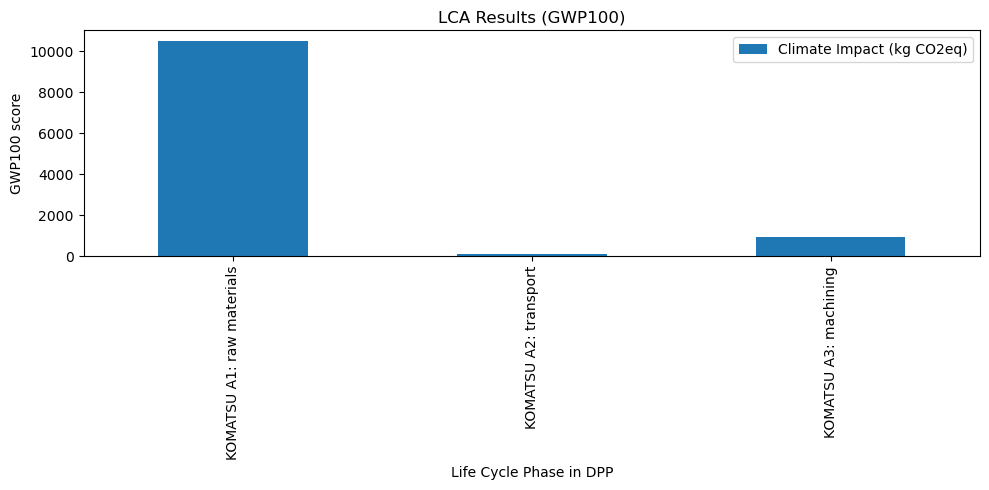

In [52]:
df_plot = df_komatsu_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("KOMATSU total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

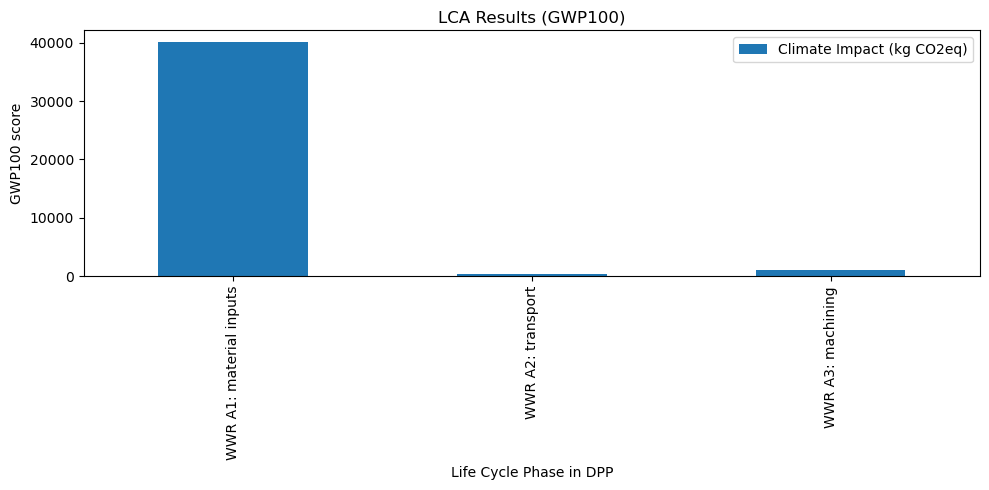

In [53]:
df_plot = df_wwr_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("WWR total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

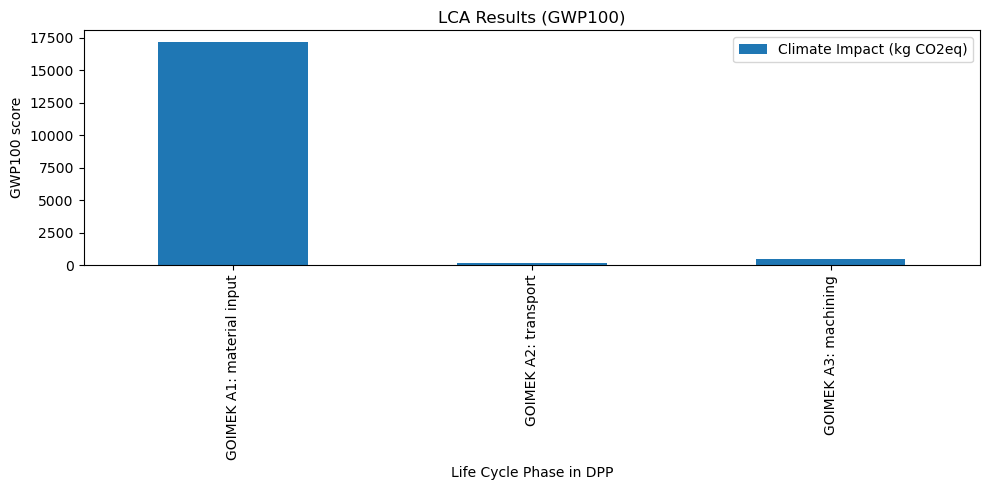

In [54]:
df_plot = df_goimek_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("GOIMEK total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()